# Figure3 Event Leads

Reproduces panels used in the main manuscript. Generated files are written to `logs/scripts/figure3_event_leads/`.


In [1]:
import os, sys
from pathlib import Path

if Path(os.getcwd()).stem == 'scripts':
    ROOT = Path(os.getcwd()).parent
else:
    ROOT = Path(os.getcwd())

sys.path.append(str(ROOT))
os.chdir(ROOT)

In [2]:
import re
import sys
import json
import yaml
import shlex
import random
import dotenv
import signal
import logging
import datetime
import nd2py as nd
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
from socket import gethostname
from argparse import Namespace
from argparse import ArgumentParser
from nd2py.utils import init_logger
from setproctitle import setproctitle
from src.utils import add_negation_flags, tag2ansi, log_exception
from src.core import Triplet, Individual
from src.assistant import Assistant
from src.ai_scientist import AIScientist
from src.ai_scientist_parallel import AIScientistParallel
from src.utils import wrap_ansi

import warnings
# warnings.simplefilter('error', RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="nd2py")

dotenv.load_dotenv()
_logger = logging.getLogger('src')

args = Namespace(**json.load(open('data/cache/default_args.json', 'r')))
args.save_dir = './logs/scripts'
args.exp_name = 'figure3_event_leads'
args.train_period = ['all', 'all']
args.test_period = ['all', 'all']
args.a_skill_after_2004 = 0.0
args.debug = True

## Build Save Path
if args.exp_name is None:
    now = datetime.now()
    date = now.strftime("%Y%m%d")
    curr = now.strftime("%H%M%S")
    host = gethostname()
    exp_name = f'{date}_{args.name}_{curr}_{host}'
    exp_name = re.compile(r'[ <>:"/\\|?*\x00-\x1f]').sub('_', exp_name.strip())
    exp_name = exp_name or 'unnamed'
    exp_name = exp_name[:255] # Max filename length on most filesystems
    args.exp_name = exp_name
save_path = Path(args.save_dir) / args.exp_name
if not save_path.exists():
    save_path.mkdir(parents=True, exist_ok=True)
else:
    _logger.warning(f"Save path {save_path} already exists.")
args.save_path = str(save_path)

## Set Random State
if args.random_state is None:
    args.random_state = random.randint(0, 2**31 - 1)
## Set Command
args.command = ' '.join(map(shlex.quote, [sys.executable, *sys.argv]))

## Init Logger
init_logger(
    "src", 
    exp_name=args.exp_name, 
    log_file=save_path / "info.log", 
    info_level='debug' if args.debug else 'info',
    show_lineno_for_all_levels=args.debug,
)
nd2py_logger = logging.getLogger("nd2py")
nd2py_logger.setLevel(_logger.level)
nd2py_logger.handlers = _logger.handlers.copy()

## Save Args
args_path = save_path / "args.json"
if args_path.exists():
    i = 1
    while args_path.with_suffix(f".json.{i}").exists(): i += 1
    args_path.rename(args_path.with_suffix(f".json.{i}"))
    _logger.warning(f"args.json already exists, backup to args.json.{i}")
_logger.note(f"Args: {args}")
with open(args_path, "w") as f:
    json.dump(vars(args), f, indent=4, ensure_ascii=False)

# Start the main process
setproctitle(f"{args.exp_name}@ZihanYu")

## Load Assistant
assistant = Assistant(args)
## Load Data
# 加载变量
variables = assistant.load_variables()
# 加载数据
df_all = assistant.load_data(normalize_co2=False)
# 划分数据
if True:
    train_start, train_end = args.train_period
    test_start, test_end = args.test_period
    train_start = pd.Period(train_start, freq='M') if train_start != 'all' else df_all.index[0]
    train_end = pd.Period(train_end, freq='M') if train_end != 'all' else df_all.index[-1]
    test_start = pd.Period(test_start, freq='M') if test_start != 'all' else df_all.index[0]
    test_end = pd.Period(test_end, freq='M') if test_end != 'all' else df_all.index[-1]
    df_train = df_all.loc[train_start:train_end]
    df_test = df_all.loc[test_start:test_end]
elif False:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
else:
    df_train = df_all.loc[pd.Period(year=1979, month=1, freq='M'):pd.Period(year=1999, month=12, freq='M')]
    df_test = df_all.loc[pd.Period(year=2000, month=1, freq='M'):pd.Period(year=2022, month=12, freq='M')]
# 准备拓扑
edge_list, num_nodes = assistant.load_topology()
# 打印日志
_logger.info(
    f"Data loaded: {len(df_all)} samples, "
    f"where {len(df_train)}({len(df_train)/len(df_all):.2%}) "
    f"from {df_train.index[0]} to {df_train.index[-1]} for training, "
    f"and {len(df_test)}({len(df_test)/len(df_all):.2%}) "
    f"from {df_test.index[0]} to {df_test.index[-1]} for testing."
)
_logger.info(
    f"Variables: " + ", ".join(f'{var_name}({len(sub_df)})' for var_name, sub_df in df_all.T.groupby(level=0)) + "."
)
## Load Seed Individuals
seed_individuals = assistant.load_seed_individuals()

## Initialize Runner
Runner = AIScientistParallel if args.parallel else AIScientist
kwargs = dict(
    args=args,
    assistant=assistant,
    variables=variables,
    binary=[
        getattr(nd, name) for name in args.binary
        # nd.Add, nd.Sub, nd.Mul, nd.Div
    ],
    unary=[
        getattr(nd, name) for name in args.unary
        # nd.Sin, nd.Cos,
        # nd.Exp, nd.LogAbs,
        # nd.Sigmoid, nd.Tanh,
        # nd.Pow2, nd.Pow3, nd.SqrtAbs,
        # nd.Aggr, nd.Readout, nd.Sour, nd.Targ,
    ],
    edge_list=edge_list,
    num_nodes=num_nodes,
    seed_individuals=seed_individuals,
)
_logger.note(f"Initializing Runner with args: {kwargs}")
est = Runner(**kwargs)
# Set Clip Bounds
est.evaluator.simulator.set_clip_bounds(df_all, clip_factor=args.clip_factor)

Save path logs/scripts/figure3_event_leads already exists.
[figure3_event_leads|src|W|Oct15 10:35:30|0:00:00.003060] (../../../../../../tmp/ipykernel_2225904/109517684.py:85) args.json already exists, backup to args.json.4
[figure3_event_leads|src|N|Oct15 10:35:30|0:00:00.005107] (../ClimateModelCode/nd2py_package/nd2py/utils/logger.py:62) Args: Namespace(name='Reduce_320_230_368', setting='only_co2', exp_name='figure3_event_leads', llm_model=None, llm_provider=None, seed_individuals=['co2_320_230_368'], load_seed_individuals=[], use_seed_individuals_only=True, num_workers=24, parallel=True, timeout=240, population_size=200, n_iter=300, programs_per_prompt=2, generate_per_prompt=8, expire_iter=1, keep_best=False, random_state=1581316702, score_func='tanh', a_rmse=0.0, a_trajrmse=0.0, a_skill_cv_sum=0.0, a_skill_cv_sum_inner=0.0, a_skill_cv_mean=0.0, a_ENSO_skill_cv=1.0, a_Total_skill_cv=10.0, a_skill_sum_inner=0.0, a_skill_sum=0.0, a_skill_mean=0.0, a_ENSO_skill=0.0, a_IOB_skill=0.0, a

In [3]:
args.a_rmse = 0.0
args.a_trajrmse = 0.0
args.a_skill_cv_sum = 0.0
args.a_skill_cv_sum_inner = 0.0
args.a_skill_cv_mean = 0.0
args.a_ENSO_skill_cv = 1.0
args.a_ATL3_skill_cv = 1.0
args.a_SASD_skill_cv = 1.0
args.a_Total_skill_cv = 10.0
args.a_skill_sum_inner = 0.0
args.a_skill_sum = 0.0
args.a_skill_mean = 0.0
args.a_ENSO_skill = 0.0
args.a_IOB_skill = 0.0
args.a_SASD_skill = 0.0
args.a_Total_skill = 0.0
args.a_skill_after_2004 = 1.0
args.a_length = 1.0
args.a_params = 0.0
args.a_std = 0.25
args.a_skewness = 0.25
args.a_spectrum = 0.25
args.a_leadlag = 0.25
args.a_forecast = 0.0
args.a_contain_co2 = 0.0
args.max_month = 40
args.a_correlation_auc_sum = 0.0
args.a_correlation_auc_cv_sum = 0.0

args.damp = 1e-1
args.atol = 1e-6
args.btol = 1e-6
args.iter_lim = None

In [4]:
baseline_indiv = assistant.load_baseline_indiv()

def evaluate3(indiv, df_test, df_train=None):
    if df_train is None:
        df_train = df_test

    # Set Ground Truth Results
    _logger.info(f"Calculating ground truth result on test data...")
    est.evaluator.set_ground_truth_result(df_test)
    # Set XRO Baseline Results
    _logger.info(f"Evaluating XRO on test data as baseline...")
    baseline_dynamics = assistant.triplet_to_dynamics(baseline_indiv.triplet)
    baseline_indiv.dynamics, mse = est.evaluator.fitter.fit_parameters(baseline_dynamics, df_train, nonlinear=True)
    est.evaluator.set_baseline_result(baseline_indiv.dynamics, df_test, use_tqdm=True)
    baseline_indiv.fitness, baseline_indiv.detail = est.evaluator.get_fitness(est.evaluator.baseline_result)
    baseline_log = est.get_log_for_indiv(baseline_indiv)
    if False:
        _logger.info(tag2ansi(f"[green]Evaluate XRO on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
        _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in baseline_log.items())))

    est.evaluator.set_fitness(indiv, df_test, df_fit=df_train, use_tqdm=True)
    log = est.get_log_for_indiv(indiv)
    _logger.info(tag2ansi(f"[green]Evaluate on Test Data from {df_test.index[0]} to {df_test.index[-1]} (parameters are fitted on Train Data from {df_train.index[0]} to {df_train.index[-1]})[reset]"))
    _logger.info(tag2ansi("\n".join(f"[#66CCFF]{k.strip('\n')}[reset]={wrap_ansi(tag2ansi(v), 150).strip('\n')}" for k, v in log.items())))

In [5]:
# df_all = assistant.load_data(normalize_co2=True)
df_all = assistant.load_data(normalize_co2=False)

triplet = assistant.program_to_triplet("""
def get_equations(t, x, h, u_co2, mode, nl_params):
    coeff = 1 + cos(t) + sin(t) + sin(0.50 * t) + sin(2 * t)
    dx_dt = x + mode['ENSO'] * h + log(u_co2) + aggr( sour(x) + tanh(0.70 * sour(h)) * (1.00 + 1.20 * targ(x) + 1.10 * readout(x)) )
    dh_dt = h + readout(x) ** 2               + aggr( sour(x) + tanh(2.00 * sour(h)) * (0.65 + 0.60 * targ(h) + 0.10 * readout(x)) )
    return coeff, dx_dt, dh_dt
""")
indiv = Individual(
    uuid=None,
    n_iter=None,
    source=None,
    parents=[],
    program=assistant.triplet_to_program(triplet),
    triplet=triplet,
    dynamics=assistant.triplet_to_dynamics(triplet),
)

args.a_skill_after_2004 = 0.0
args.use_nfold_cv = False
args.use_l3yo_cv = False
# evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.257094] (src/assistant/data_loader.py:55) Detrending ENSO SST with coefficients: [-7.14225957e-07  3.27857303e-04  8.16754329e-02]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.259663] (src/assistant/data_loader.py:55) Detrending NPMM SST with coefficients: [ 5.23786876e-06 -5.07198219e-03  1.14418764e+00]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.261429] (src/assistant/data_loader.py:55) Detrending SPMM SST with coefficients: [-6.20970905e-07 -3.72185672e-04  3.92080518e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.263224] (src/assistant/data_loader.py:55) Detrending IOB SST with coefficients: [ 1.84648014e-06 -1.01057274e-03  8.39776510e-02]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.265439] (src/assistant/data_loader.py:55) Detrending IOD SST with coefficients: [-1.41512104e-06  1.72745765e-03 -5.17341840e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00

[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.297824] (src/assistant/data_loader.py:86) Detrending ENSO OHC with coefficients: [ 4.20809405e-06 -3.86123947e-03  6.56778191e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.300422] (src/assistant/data_loader.py:86) Detrending NPMM OHC with coefficients: [ 2.19170127e-06 -2.78250537e-03  8.14489038e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.302782] (src/assistant/data_loader.py:86) Detrending SPMM OHC with coefficients: [-1.84291879e-06  1.95872346e-03 -3.46851706e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.305237] (src/assistant/data_loader.py:86) Detrending IOB OHC with coefficients: [ 4.58999114e-06 -4.10462486e-03  7.64498608e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00.307725] (src/assistant/data_loader.py:86) Detrending IOD OHC with coefficients: [ 2.98321953e-07 -9.72895190e-05 -1.46027714e-01]
[figure3_event_leads|data_loader|D|Oct15 10:35:30|0:00:00

In [6]:
args.use_nfold_cv = False
args.use_l3yo_cv = True
args.lnyo_cv_N = 5
args.lnyo_cv_N_bias = 1
args.max_month = 36
evaluate3(indiv, df_all.loc['1979-01':'2024-12'], df_all.loc['1979-01':'2024-12'])

[figure3_event_leads|src|I|Oct15 10:35:31|0:00:00.596328] (../../../../../../tmp/ipykernel_2225904/1242833028.py:8) Calculating ground truth result on test data...
[figure3_event_leads|src|I|Oct15 10:35:35|0:00:05.342803] (../../../../../../tmp/ipykernel_2225904/1242833028.py:11) Evaluating XRO on test data as baseline...


Output()

Output()

Output()

Output()

[figure3_event_leads|src|I|Oct15 10:38:13|0:02:42.842296] (../../../../../../tmp/ipykernel_2225904/1242833028.py:23) Evaluate on Test Data from 1979-01 to 2024-12 (parameters are fitted on Train Data from 1979-01 to 2024-12)
[figure3_event_leads|src|I|Oct15 10:38:13|0:02:42.844933] (../../../../../../tmp/ipykernel_2225904/1242833028.py:24) Info=None from None() at Iter None
        Fitness=1.139330
        Skills=x_ENSO=32 month; x_NPMM=17 month; x_SPMM=5 month; x_IOB=29 month; x_IOD=13 month; x_SIOD=19 month; x_TNA=10 month; x_ATL3=5 month; x_SASD=5 month; h_E
        NSO=24 month; h_NPMM=23 month; h_SPMM=20 month; h_IOB=33 month; h_IOD=24 month; h_SIOD=29 month; h_TNA=15 month; h_ATL3=6 month; h_SASD=15 month;Total
         SST=135 month;Total Z20=189 month;Total=324 month
        Skills%=x_ENSO=+68.42%;x_NPMM=-5.56%;x_SPMM=+0.00%;x_IOB=+26.09%;x_IOD=+116.67%;x_SIOD=+18.75%;x_TNA=+0.00%;x_ATL3=+25.00%;x_SASD=-28.57%;h_ENSO=+41.18%;h_NPM
        M=+21.05%;h_SPMM=+25.00%;h_IOB=+106.25%

# Cross Validation 预报

In [7]:
OUR_PREDICTION = indiv.detail['PREDICTION_cv']
XRO_PREDICTION = baseline_indiv.detail['PREDICTION_cv']

/tmp/ipykernel_2225904/1547733559.py:57: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.swarmplot(data=df_plot, hue='name', y='lead', x='event', dodge=True, ax=ax, color='k', alpha=0.7, size=2, legend=False)
/tmp/ipykernel_2225904/1547733559.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['El Niño', 'La Niña'])


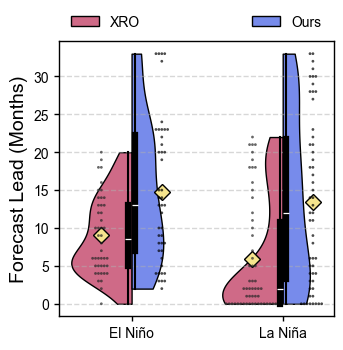

event,El Niño,La Niña
name,,
Ours,14.727273,13.425926
XRO,9.068182,5.944444


event
El Niño    0.624060
La Niña    1.258567
dtype: float64

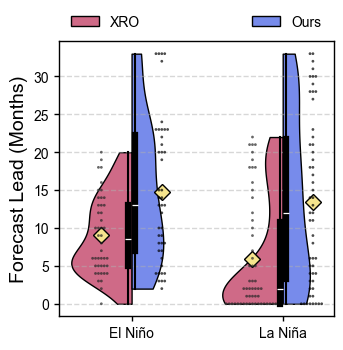

In [ ]:
import seaborn as sns
from nd2py.utils.plot import get_fig

# repeat_month = 1
repeat_month = 3

if True:
    df_plot = (
        pd.merge(
            est.evaluator.get_forecast_month(
                # est.evaluator.baseline_result['PREDICTION'], 
                XRO_PREDICTION,
                return_raw=True, repeat_month=repeat_month
            )
            .reset_index(),
            est.evaluator.get_forecast_month(
                # indiv.detail['PREDICTION'], 
                OUR_PREDICTION,
                return_raw=True, repeat_month=repeat_month
            )
            .reset_index(),
            on=['stop', 'event'],
            suffixes=('_XRO', '_Ours')
        )
        .melt(
            id_vars=['stop', 'event'],
            var_name='name',
            value_name='lead',
        )
        .pipe(
            lambda df: df.assign(name=df['name'].replace({'lead_XRO': 'XRO', 'lead_Ours': 'Ours'}))
        )
    )
    df_plot = df_plot[
        df_plot['stop'].str.contains('Dec') 
        | df_plot['stop'].str.contains('Nov')
        | df_plot['stop'].str.contains('Jan')
    ] 
    fi, fig, axes = get_fig(1, 1, AW=6.987777777777778, A_ratio=1, HS=5, VS=15, LM=5, TM=5, RM=5, BM=5, dpi=100, fontsize=14, lw=1)
    ax = axes[0]
    sns.violinplot(
        data=df_plot,
        hue="name",
        y="lead",
        x="event",
        split=True,
        ax=ax,
        cut=0,
        linewidth=fi['lw'],
        linecolor="k",
        palette=['#cf6a87', '#778beb'], 
        saturation=1.0,
        hue_order=['XRO', 'Ours'],
        order=['El Niño', 'La Niña'],
        common_norm=True,
    )
    sns.swarmplot(data=df_plot, hue='name', y='lead', x='event', dodge=True, ax=ax, color='k', alpha=0.7, size=2, legend=False)
    ax.legend(title=None, loc='lower center', frameon=False, ncol=2, bbox_to_anchor=(0, 1, 1, 0), mode='expand')
    ax.set_xticklabels(['El Niño', 'La Niña'])
    ax.set_xlabel('')
    ax.set_ylabel('Forecast Lead (Months)')
    ax.grid(axis='y', zorder=0, alpha=0.5, linestyle='--')

    # 获取分类的x位置
    for i, t in enumerate(['El Niño', 'La Niña']):
        dodge_offset = 0.2 # seaborn dodge 后的偏移量（经验值，大约是 0.2）

        # 一一对应画线
        # df_t = df_plot[df_plot['event'] == t].fillna(0)
        # df_xro_t = df_t[df_t['name'] == 'XRO'].sort_index()
        # df_ours_t = df_t[df_t['name'] == 'Ours'].sort_index()
        # for (y1, y2) in zip(df_xro_t['lead'], df_ours_t['lead']):
        #     color = 'red' if y2 - y1 > 0 else 'black'
        #     ax.plot([i - dodge_offset, i + dodge_offset], [y1, y2], color=color, alpha=0.5, linewidth=fi['lw'])

        # df_annot = df_plot[df_plot['event'].eq(t) & df_plot['name'].eq('Ours')]
        # for y in df_annot['lead'].unique():
        #     tmp = df_annot.loc[df_annot['lead'] == y, 'stop']
        #     text = '/'.join([i[2:] for i in tmp])
        #     text = ' ' * max(0, len(tmp)-2) + text
        #     x = i + dodge_offset
        #     ax.text(x, y, f' {text}', ha='left', va='center', fontsize=0.7*fi['fontsize'])

        # 用黄色菱形显示均值
        df_t = df_plot[df_plot['event'] == t]
        mean_xro = df_t[df_t['name'] == 'XRO']['lead'].mean()
        mean_ours = df_t[df_t['name'] == 'Ours']['lead'].mean()
        ax.plot(i - dodge_offset, mean_xro, marker='D', color='#f6e58d', markersize=8, markeredgecolor='k', markeredgewidth=fi['lw'])
        ax.plot(i + dodge_offset, mean_ours, marker='D', color='#f6e58d', markersize=8, markeredgecolor='k', markeredgewidth=fi['lw'])
    
    fig.savefig(save_path / 'Fig3f.svg', bbox_inches='tight', dpi=300, transparent=True)
    fig.savefig(save_path / 'Fig3f.pdf', bbox_inches='tight', dpi=300, transparent=True)
    fig.savefig(save_path / 'Fig3f.png', bbox_inches='tight', dpi=300, transparent=True)

    df_tmp = df_plot.groupby(['name', 'event'])['lead'].mean().unstack()
    display(df_tmp)
    display(df_tmp.loc['Ours'] / df_tmp.loc['XRO'] - 1)